
Step 1 :Import and load

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

types_train = pd.read_csv("../data/processed/types_train.csv")
types_test = pd.read_csv("../data/processed/types_test.csv")

print(X_train.shape, types_train.shape)

(8000, 11) (8000, 5)


Step 2: Choose the types to model

In [3]:
target_types = ["TWF", "HDF", "PWF", "OSF"]

types_train[target_types].sum()

TWF    39
HDF    89
PWF    72
OSF    81
dtype: int64

Step 3: Train one model per type

In [4]:
diagnosis_models = {}

for t in target_types:
    y_tr = types_train[t]
    ratio = (y_tr == 0).sum() / (y_tr == 1).sum()

    model = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.1,
        scale_pos_weight=ratio,
        eval_metric="logloss",
        random_state=42
    )
    model.fit(X_train, y_tr)

    diagnosis_models[t] = model
    print(t, "trained | scale_pos_weight =", round(ratio, 1))

TWF trained | scale_pos_weight = 204.1
HDF trained | scale_pos_weight = 88.9
PWF trained | scale_pos_weight = 110.1
OSF trained | scale_pos_weight = 97.8


Step 4: Evaluate each model

In [5]:
for t in target_types:
    y_te = types_test[t]
    y_pred = diagnosis_models[t].predict(X_test)

    print("=" * 50)
    print(t, "| real cases in test set:", y_te.sum())
    print(classification_report(y_te, y_pred, zero_division=0))

TWF | real cases in test set: 7
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1993
           1       0.22      0.29      0.25         7

    accuracy                           0.99      2000
   macro avg       0.61      0.64      0.62      2000
weighted avg       0.99      0.99      0.99      2000

HDF | real cases in test set: 26
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1974
           1       0.93      1.00      0.96        26

    accuracy                           1.00      2000
   macro avg       0.96      1.00      0.98      2000
weighted avg       1.00      1.00      1.00      2000

PWF | real cases in test set: 23
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1977
           1       0.91      0.87      0.89        23

    accuracy                           1.00      2000
   macro avg       0.95      0

Step 5: Feature importance

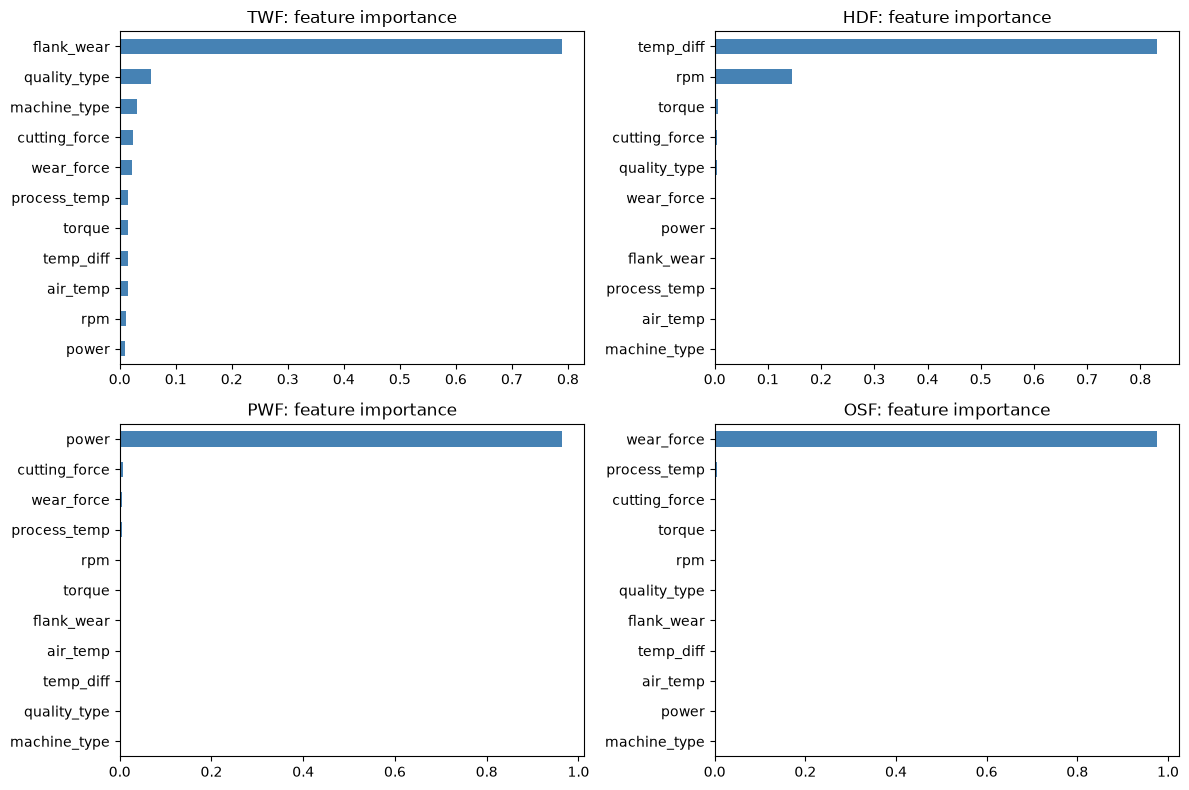

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, t in zip(axes, target_types):
    importance = pd.Series(
        diagnosis_models[t].feature_importances_, index=X_train.columns
    ).sort_values()

    importance.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"{t}: feature importance")

plt.tight_layout()
plt.show()

Step 6: Test a diagnosis on one machine

In [7]:
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

failed_rows = y_test[y_test == 1].index
row = failed_rows[0]
print("Row index:", row)

Row index: 0


In [8]:
sample = X_test.loc[[row]]

for t in target_types:
    prob = diagnosis_models[t].predict_proba(sample)[0, 1]
    print(f"{t}: {prob * 100:.1f}%")

TWF: 83.8%
HDF: 0.0%
PWF: 0.0%
OSF: 0.0%


In [9]:
types_test.loc[row, target_types]

TWF    1
HDF    0
PWF    0
OSF    0
Name: 0, dtype: int64

Step 7: Save the diagnosis models

In [10]:
joblib.dump(diagnosis_models, "../models/diagnosis_models.joblib")

['../models/diagnosis_models.joblib']